In [8]:
import torch
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt

from sklearn.manifold import TSNE

In [9]:

training_data = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

test_data = datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)


train_dataloader = torch.utils.data.DataLoader(training_data, batch_size=128, shuffle=True)
test_dataloader = torch.utils.data.DataLoader(test_data, batch_size=128, shuffle=False)



In [10]:
loss_fn = torch.nn.MSELoss()

class Encoder(torch.nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.latent_dim = latent_dim
        self.flatten = torch.nn.Flatten()
        self.linear_relu_stack = torch.nn.Sequential(
            torch.nn.Linear(28 * 28, 512),
            torch.nn.ReLU(),
            torch.nn.Linear(512, 256),
            torch.nn.ReLU(),
            torch.nn.Linear(256, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, latent_dim),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits
    
class Decoder(torch.nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.latent_dim = latent_dim
        self.linear_relu_stack = torch.nn.Sequential(
            torch.nn.Linear(latent_dim, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, 256),
            torch.nn.ReLU(),
            torch.nn.Linear(256, 512),
            torch.nn.ReLU(),
            torch.nn.Linear(512, 28 * 28),
            torch.nn.Sigmoid()
        )

    def forward(self, x):
        logits = self.linear_relu_stack(x)
        return logits.view(-1, 1, 28, 28)
    
class Autoencoder(torch.nn.Module):
    def __init__(self, latent_dim= 32):
        super().__init__()
        self.encoder = Encoder(latent_dim=latent_dim)
        self.decoder = Decoder(latent_dim=latent_dim)
    
    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded
    


In [11]:

def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, _) in enumerate(dataloader):
        pred = model(X)
        loss = loss_fn(pred, X)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
            
            
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, _ in dataloader:
            pred = model(X)
            test_loss += loss_fn(pred, X).item()
    test_loss /= num_batches
    print(f"Test Error: \n Avg loss: {test_loss:>8f} \n")
    

ae_model = Autoencoder(latent_dim=32)
optimizer = torch.optim.Adam(ae_model.parameters(), lr=1e-3)
epochs = 8
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, ae_model, loss_fn, optimizer)
    test(test_dataloader, ae_model, loss_fn)


Epoch 1
-------------------------------
loss: 0.231879  [    0/60000]
loss: 0.062729  [12800/60000]
loss: 0.052474  [25600/60000]
loss: 0.044788  [38400/60000]
loss: 0.035825  [51200/60000]
Test Error: 
 Avg loss: 0.032933 

Epoch 2
-------------------------------
loss: 0.035725  [    0/60000]
loss: 0.031387  [12800/60000]
loss: 0.027172  [25600/60000]
loss: 0.028766  [38400/60000]
loss: 0.025100  [51200/60000]
Test Error: 
 Avg loss: 0.024252 

Epoch 3
-------------------------------
loss: 0.023051  [    0/60000]
loss: 0.023709  [12800/60000]
loss: 0.022033  [25600/60000]
loss: 0.020459  [38400/60000]
loss: 0.020757  [51200/60000]
Test Error: 
 Avg loss: 0.020070 

Epoch 4
-------------------------------
loss: 0.019131  [    0/60000]
loss: 0.020415  [12800/60000]
loss: 0.020040  [25600/60000]
loss: 0.020279  [38400/60000]
loss: 0.018585  [51200/60000]
Test Error: 
 Avg loss: 0.017709 

Epoch 5
-------------------------------
loss: 0.017317  [    0/60000]
loss: 0.017197  [12800/60000]


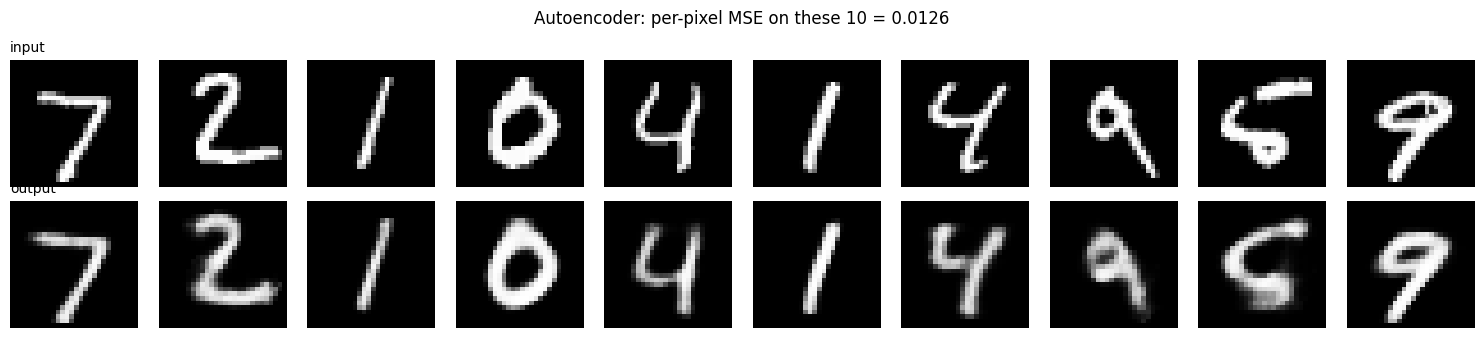

In [12]:
def show_reconstructions(model, dataset, n=8):
    model.eval()
    device = next(model.parameters()).device
    x = torch.stack([dataset[i][0] for i in range(n)]).to(device)
    with torch.no_grad():
        out = model(x)
    # Autoencoder returns a tensor, VQVAE returns (x_recon, vq_loss)
    x_hat = out[0] if isinstance(out, tuple) else out

    fig, axes = plt.subplots(2, n, figsize=(1.5 * n, 3.4))
    for i in range(n):
        # Fixed vmin/vmax so imshow doesn't auto-stretch contrast and hide blur
        axes[0, i].imshow(x[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
        axes[1, i].imshow(x_hat[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
        axes[0, i].axis("off")
        axes[1, i].axis("off")
    axes[0, 0].set_title("input", loc="left", fontsize=10)
    axes[1, 0].set_title("output", loc="left", fontsize=10)

    mse = torch.mean((x_hat - x) ** 2).item()
    fig.suptitle(f"{type(model).__name__}: per-pixel MSE on these {n} = {mse:.4f}")
    plt.tight_layout()
    plt.show()
    
show_reconstructions(ae_model, test_data, n=10)

c:\Users\feder\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\feder\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\feder\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\feder\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

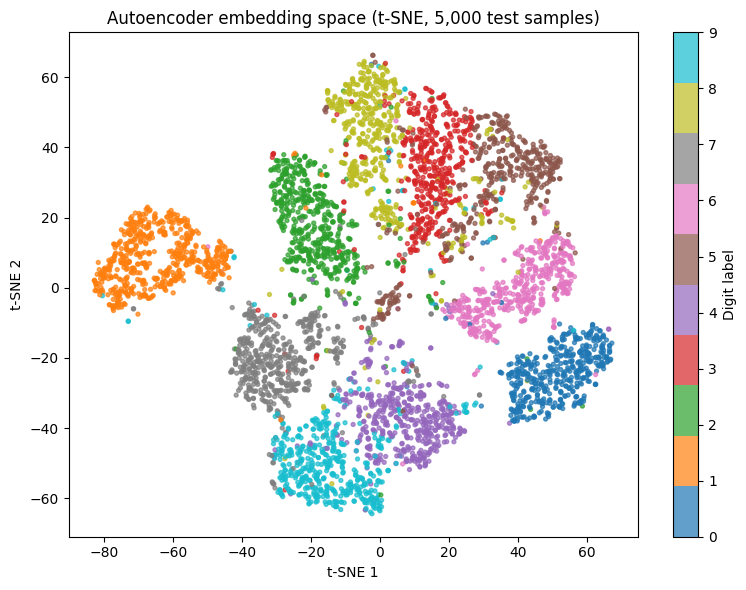

In [13]:
max_samples = 5000
ae_model.eval()
device = next(ae_model.parameters()).device

latent_batches = []
label_batches = []
n_samples = 0

with torch.no_grad():
    for images, labels in test_dataloader:
        remaining = max_samples - n_samples
        if remaining <= 0:
            break

        images = images.to(device)
        count = min(len(images), remaining)
        latent_batches.append(ae_model.encoder(images[:count]).cpu())
        label_batches.append(labels[:count].cpu())
        n_samples += count

latents = torch.cat(latent_batches).numpy()
labels = torch.cat(label_batches).numpy()

points = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto",
).fit_transform(latents)

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    points[:, 0], points[:, 1],
    c=labels, cmap="tab10", s=8, alpha=0.7
)
ax.set_title("Autoencoder embedding space (t-SNE, 5,000 test samples)")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
fig.colorbar(scatter, ax=ax, ticks=range(10), label="Digit label")
plt.tight_layout()
plt.show()

In [14]:
import itertools

class VectorQuantizer(torch.nn.Module):
    def __init__(self, num_embeddings, embedding_dim, commitment_cost):
        super().__init__()
        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim
        self.commitment_cost = commitment_cost

        self.embeddings = torch.nn.Embedding(num_embeddings, embedding_dim)
        # Placeholder only: overwritten by init_from_samples before training
        self.embeddings.weight.data.uniform_(-1 / num_embeddings, 1 / num_embeddings)
        # How often each code was picked since the last restart (training only)
        self.register_buffer("usage", torch.zeros(num_embeddings, dtype=torch.long))

    def nearest_code(self, z_e_flattened):
        distances = (
            torch.sum(z_e_flattened ** 2, dim=1, keepdim=True)
            + torch.sum(self.embeddings.weight ** 2, dim=1)
            - 2 * torch.matmul(z_e_flattened, self.embeddings.weight.t())
        )
        return torch.argmin(distances, dim=1)

    @torch.no_grad()
    def init_from_samples(self, z, n_iters=10):
        # k-means++ seeding: each new center is sampled far from the existing ones
        centers = z[torch.randint(len(z), (1,))]
        for _ in range(1, self.num_embeddings):
            d = torch.cdist(z, centers).min(dim=1).values ** 2
            centers = torch.cat([centers, z[torch.multinomial(d / d.sum(), 1)]])
        # A few Lloyd iterations to move the centers to their cluster means
        for _ in range(n_iters):
            assign = torch.cdist(z, centers).argmin(dim=1)
            for k in range(self.num_embeddings):
                members = z[assign == k]
                if len(members) > 0:
                    centers[k] = members.mean(dim=0)
        self.embeddings.weight.data.copy_(centers)

    @torch.no_grad()
    def restart_dead_codes(self, z_e):
        # Move every code unused since the last call onto a random current encoder output
        dead = self.usage == 0
        n_dead = int(dead.sum())
        if n_dead > 0:
            z = z_e.view(-1, self.embedding_dim)
            self.embeddings.weight.data[dead] = z[torch.randint(len(z), (n_dead,))]
        self.usage.zero_()
        return n_dead

    def forward(self, z_e):
        z_e_flattened = z_e.view(-1, self.embedding_dim)
        encoding_indices = self.nearest_code(z_e_flattened)
        if self.training:
            self.usage += torch.bincount(encoding_indices, minlength=self.num_embeddings)
        
        z_q = self.embeddings(encoding_indices).view(z_e.shape)
        
        vq_loss = (
            self.commitment_cost * torch.mean((z_q.detach() - z_e) ** 2) 
            +torch.mean((z_q - z_e.detach()) ** 2)
        )

        z_q = z_e + (z_q - z_e).detach()

        return z_q, vq_loss # latent representation and loss for backpropagation 
    
class CNNEncoder(torch.nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.latent_dim = latent_dim
        # Two stride-2 convs: 28 -> 14 -> 7 (a third would give 3, since 7 is odd)
        self.conv_stack = torch.nn.Sequential(
            torch.nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1),
            torch.nn.BatchNorm2d(32),
            torch.nn.ReLU(),
            torch.nn.Conv2d(32, 128, kernel_size=4, stride=2, padding=1),
            torch.nn.BatchNorm2d(128),
            torch.nn.ReLU(),
            torch.nn.Flatten(),
            torch.nn.Linear(128 * 7 * 7, latent_dim)
        )

    def forward(self, x):
        return self.conv_stack(x)
    
class CNNDecoder(torch.nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.latent_dim = latent_dim
        self.linear_stack = torch.nn.Sequential(
            torch.nn.Linear(latent_dim, 64 * 7 * 7),
            torch.nn.ReLU()
        )
        self.deconv_stack = torch.nn.Sequential(
            torch.nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            torch.nn.ReLU(),
            torch.nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1),
            torch.nn.Sigmoid()
        )

    def forward(self, x):
        x = self.linear_stack(x)
        x = x.view(-1, 64, 7, 7)
        return self.deconv_stack(x)


class VQVAE(torch.nn.Module):
    def __init__(self, latent_dim=32, num_embeddings=512, commitment_cost=0.25):
        super().__init__()
        self.encoder = CNNEncoder(latent_dim=latent_dim)
        self.decoder = Decoder(latent_dim=latent_dim)
        self.vq = VectorQuantizer(num_embeddings=num_embeddings, embedding_dim=latent_dim, commitment_cost=commitment_cost)

    def forward(self, x):
        z_e = self.encoder(x)
        z_q, vq_loss = self.vq(z_e)
        x_recon = self.decoder(z_q)
        return x_recon, vq_loss
    

Epoch 1
-------------------------------
recon: 0.084422  vq: 0.062909  restarted: 0  [12800/60000]
recon: 0.067085  vq: 0.011465  restarted: 7  [25600/60000]
recon: 0.067570  vq: 0.007254  restarted: 1  [38400/60000]
recon: 0.066079  vq: 0.007917  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.064166  codes used: 9/10
Code counts: [28, 1283, 2677, 0, 2024, 495, 5, 213, 1853, 1422]



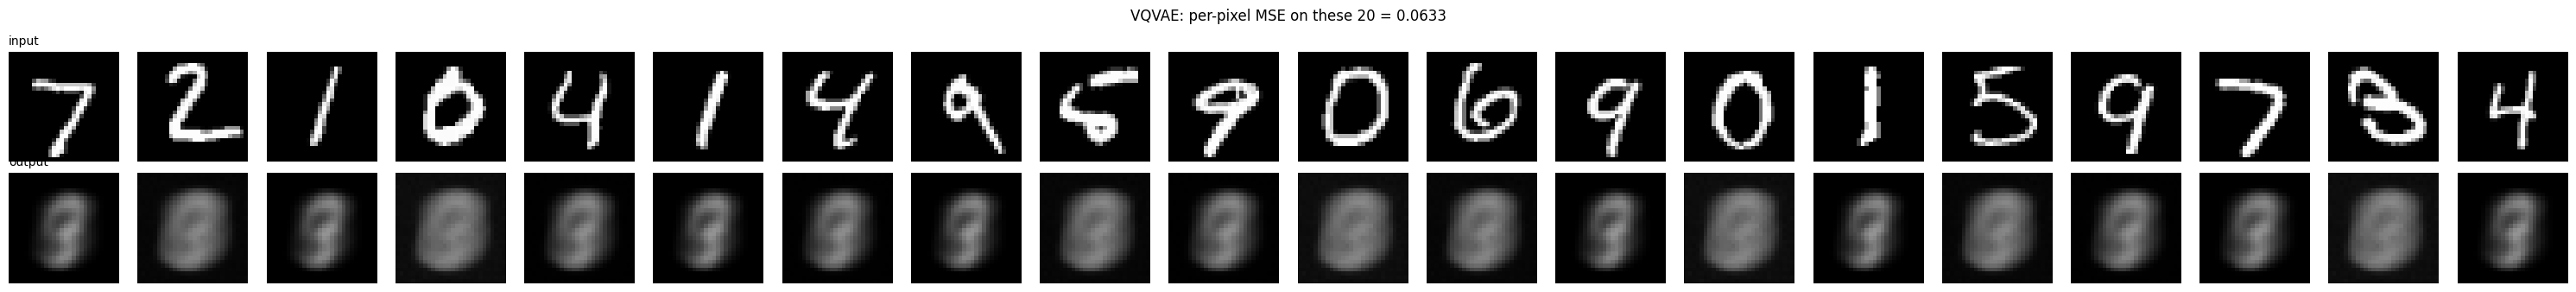

Epoch 2
-------------------------------
recon: 0.062941  vq: 0.005888  restarted: 1  [12800/60000]
recon: 0.058883  vq: 0.005046  restarted: 0  [25600/60000]
recon: 0.061553  vq: 0.003570  restarted: 1  [38400/60000]
recon: 0.061829  vq: 0.004180  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.061015  codes used: 10/10
Code counts: [37, 920, 1106, 711, 976, 1881, 273, 1, 2296, 1799]



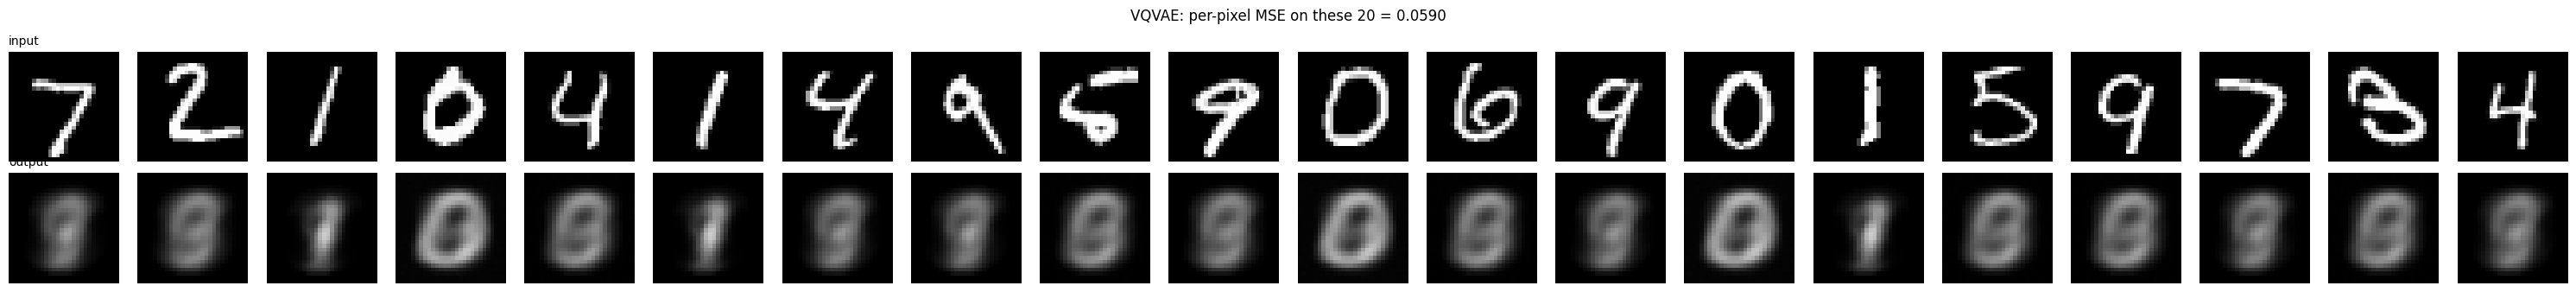

Epoch 3
-------------------------------
recon: 0.060966  vq: 0.004007  restarted: 0  [12800/60000]
recon: 0.059840  vq: 0.005134  restarted: 0  [25600/60000]
recon: 0.058535  vq: 0.006127  restarted: 0  [38400/60000]
recon: 0.062015  vq: 0.006285  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.059565  codes used: 10/10
Code counts: [458, 1330, 1226, 775, 711, 2132, 1132, 1, 1163, 1072]



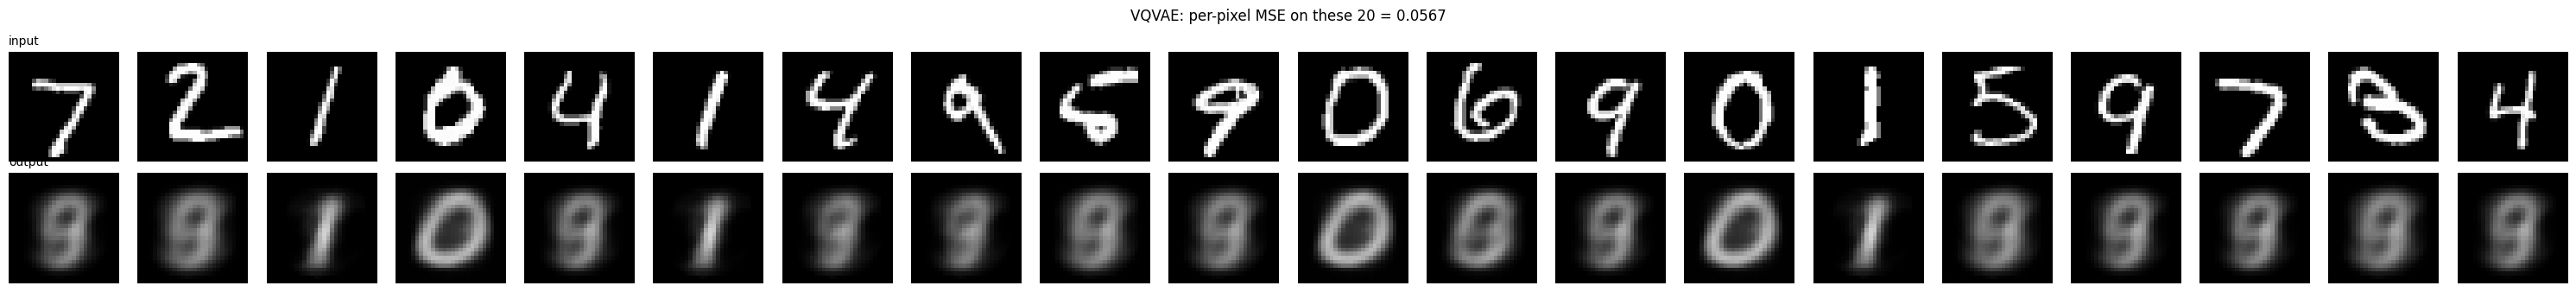

Epoch 4
-------------------------------
recon: 0.060411  vq: 0.006611  restarted: 0  [12800/60000]
recon: 0.058041  vq: 0.005714  restarted: 0  [25600/60000]
recon: 0.057715  vq: 0.006771  restarted: 0  [38400/60000]
recon: 0.060925  vq: 0.006750  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.058384  codes used: 10/10
Code counts: [994, 998, 1166, 911, 690, 2098, 997, 88, 1043, 1015]



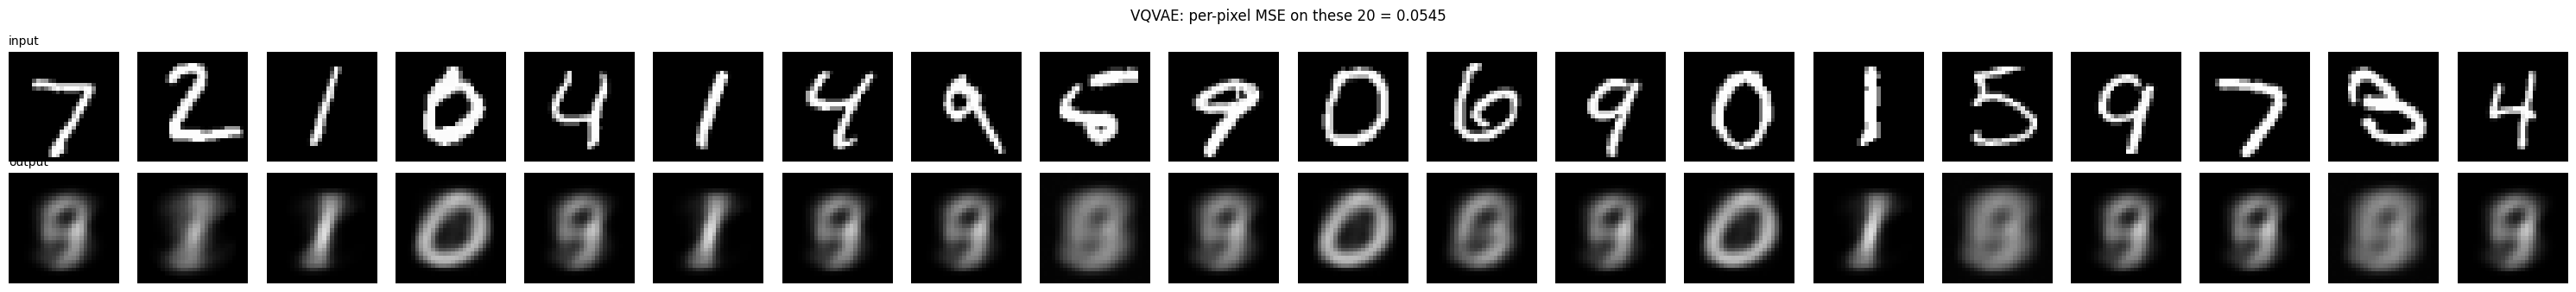

Epoch 5
-------------------------------
recon: 0.059401  vq: 0.006939  restarted: 0  [12800/60000]
recon: 0.055720  vq: 0.005612  restarted: 0  [25600/60000]
recon: 0.054893  vq: 0.007867  restarted: 0  [38400/60000]
recon: 0.059236  vq: 0.007834  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.055773  codes used: 10/10
Code counts: [1459, 1195, 1398, 770, 577, 1646, 784, 460, 766, 945]



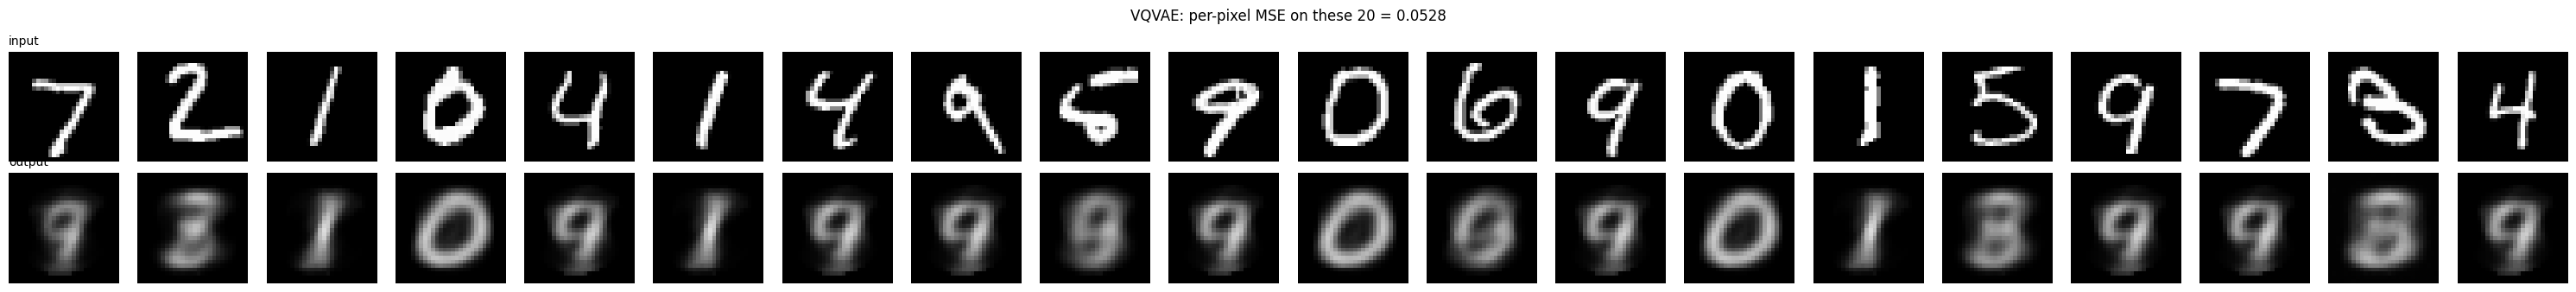

Epoch 6
-------------------------------
recon: 0.057991  vq: 0.008162  restarted: 0  [12800/60000]
recon: 0.056079  vq: 0.006574  restarted: 0  [25600/60000]
recon: 0.055456  vq: 0.008346  restarted: 0  [38400/60000]
recon: 0.054446  vq: 0.008016  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.055704  codes used: 10/10
Code counts: [1104, 971, 1397, 1145, 576, 1374, 1115, 577, 692, 1049]



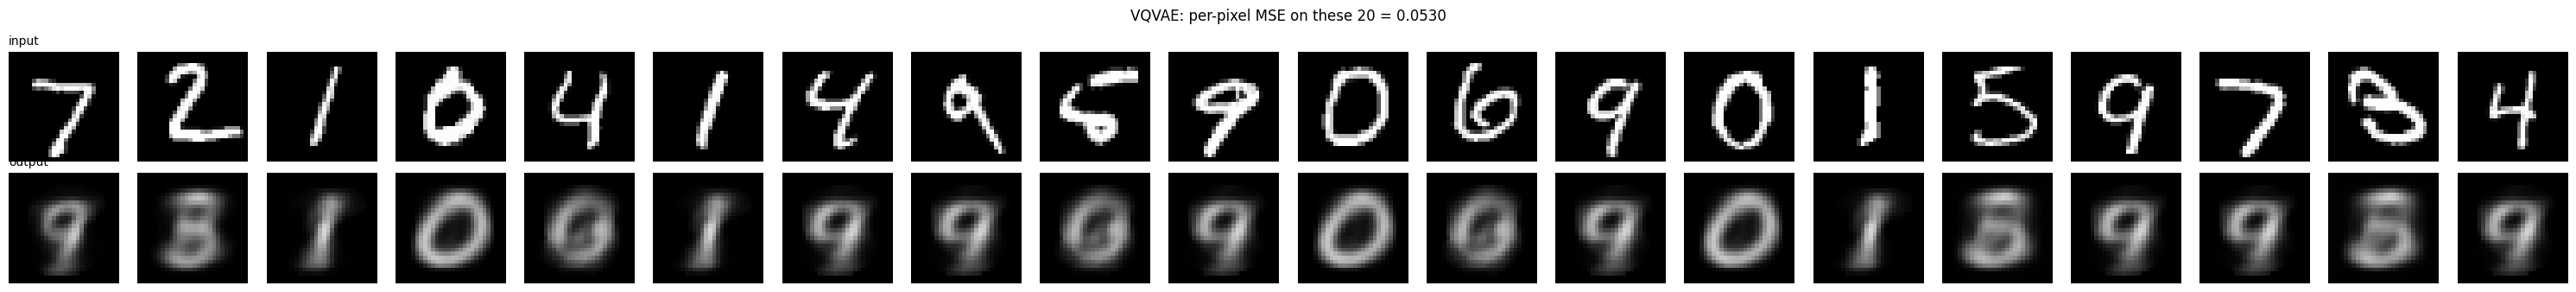

Epoch 7
-------------------------------
recon: 0.055395  vq: 0.009670  restarted: 0  [12800/60000]
recon: 0.054564  vq: 0.008087  restarted: 0  [25600/60000]
recon: 0.057768  vq: 0.008879  restarted: 0  [38400/60000]
recon: 0.056926  vq: 0.008855  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.054876  codes used: 10/10
Code counts: [1219, 1300, 1625, 1257, 636, 1227, 680, 720, 552, 784]



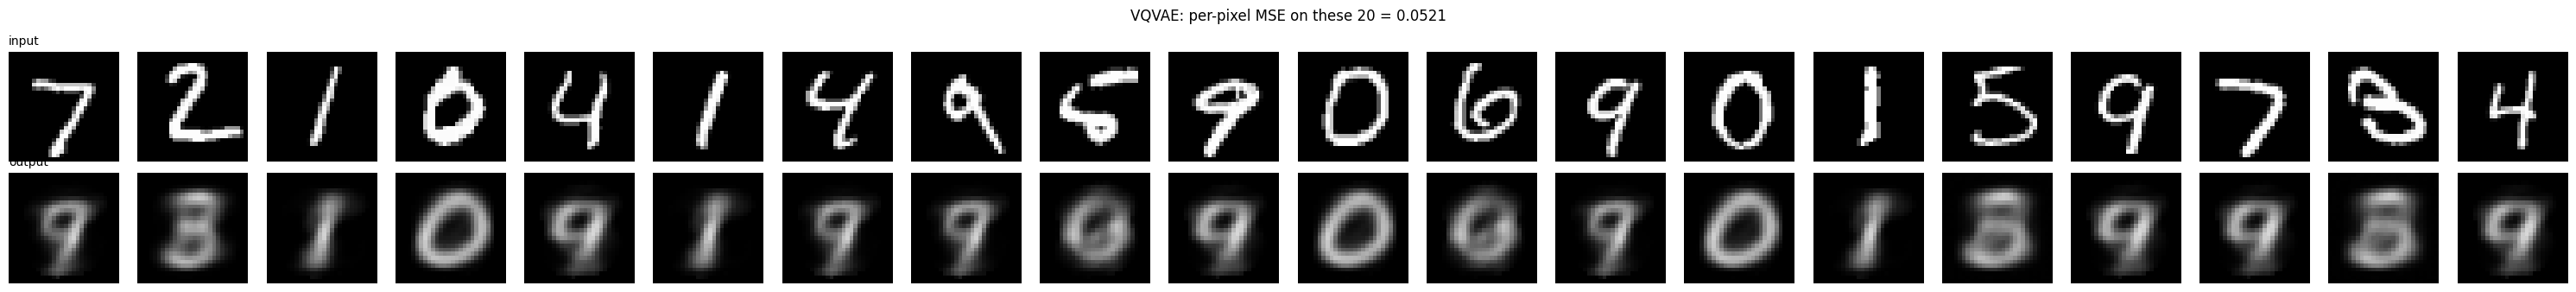

Epoch 8
-------------------------------
recon: 0.056364  vq: 0.009699  restarted: 0  [12800/60000]
recon: 0.053208  vq: 0.008064  restarted: 0  [25600/60000]
recon: 0.053756  vq: 0.008875  restarted: 0  [38400/60000]
recon: 0.055574  vq: 0.010151  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.054935  codes used: 10/10
Code counts: [1234, 1709, 1818, 1039, 787, 1207, 425, 650, 503, 628]



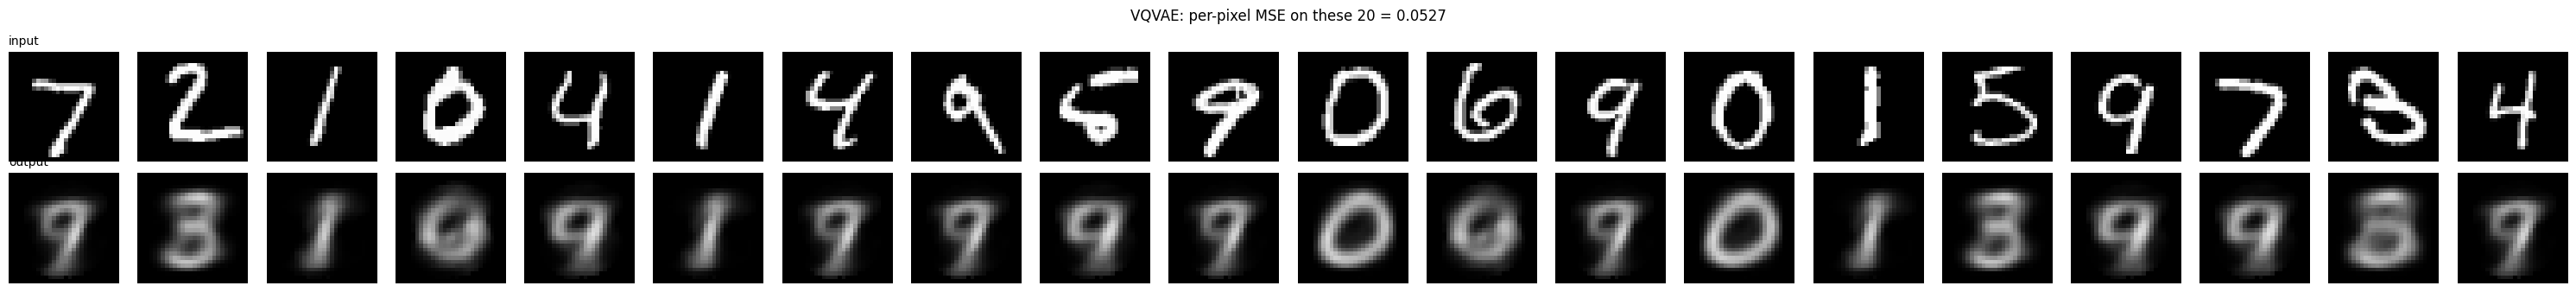

Epoch 9
-------------------------------
recon: 0.053074  vq: 0.007989  restarted: 0  [12800/60000]
recon: 0.054404  vq: 0.009614  restarted: 0  [25600/60000]
recon: 0.054377  vq: 0.009258  restarted: 0  [38400/60000]
recon: 0.056132  vq: 0.008502  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.054239  codes used: 10/10
Code counts: [1012, 1218, 1520, 1308, 855, 1335, 628, 778, 592, 754]



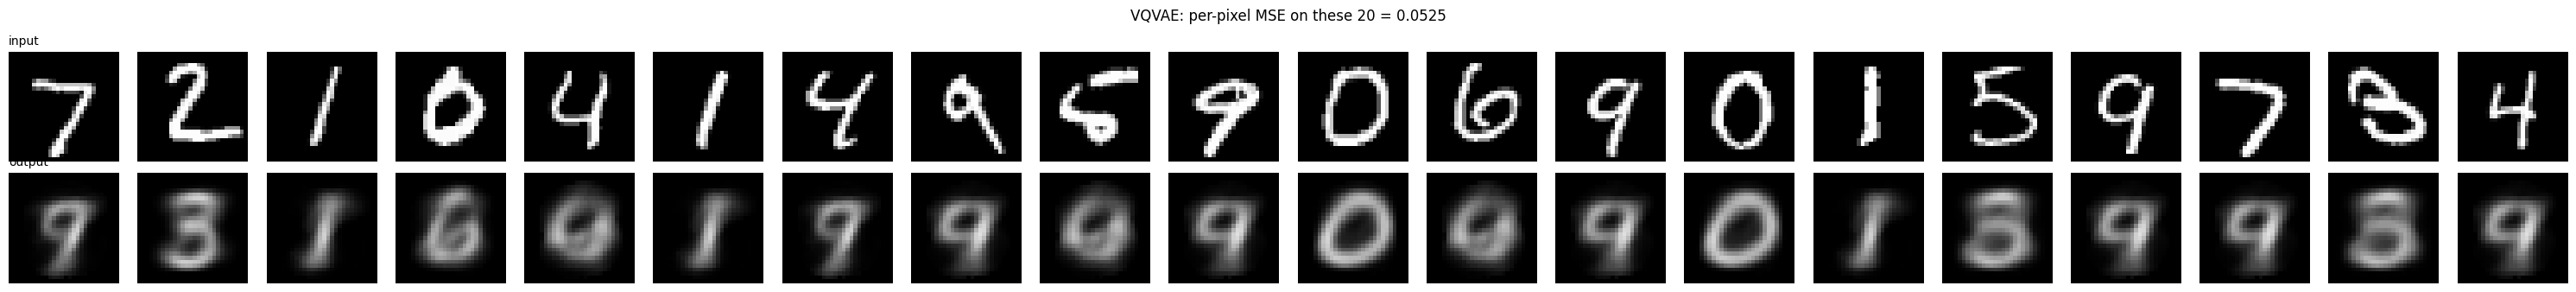

Epoch 10
-------------------------------
recon: 0.055257  vq: 0.009857  restarted: 0  [12800/60000]
recon: 0.052975  vq: 0.009478  restarted: 0  [25600/60000]
recon: 0.056918  vq: 0.008378  restarted: 0  [38400/60000]
recon: 0.055726  vq: 0.010402  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.054129  codes used: 10/10
Code counts: [1244, 1249, 1582, 1149, 927, 1408, 517, 766, 509, 649]



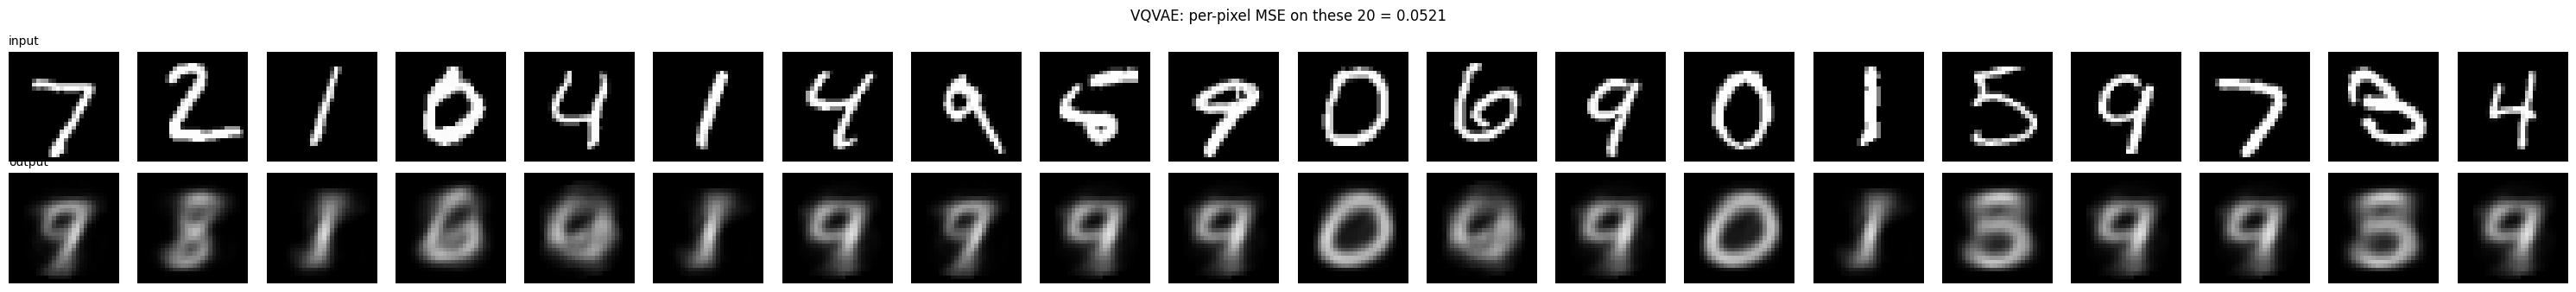

Epoch 11
-------------------------------
recon: 0.058012  vq: 0.010020  restarted: 0  [12800/60000]
recon: 0.054562  vq: 0.008864  restarted: 0  [25600/60000]
recon: 0.055589  vq: 0.010963  restarted: 0  [38400/60000]
recon: 0.053379  vq: 0.009758  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.054088  codes used: 10/10
Code counts: [1140, 1493, 1611, 1000, 907, 1360, 425, 651, 736, 677]



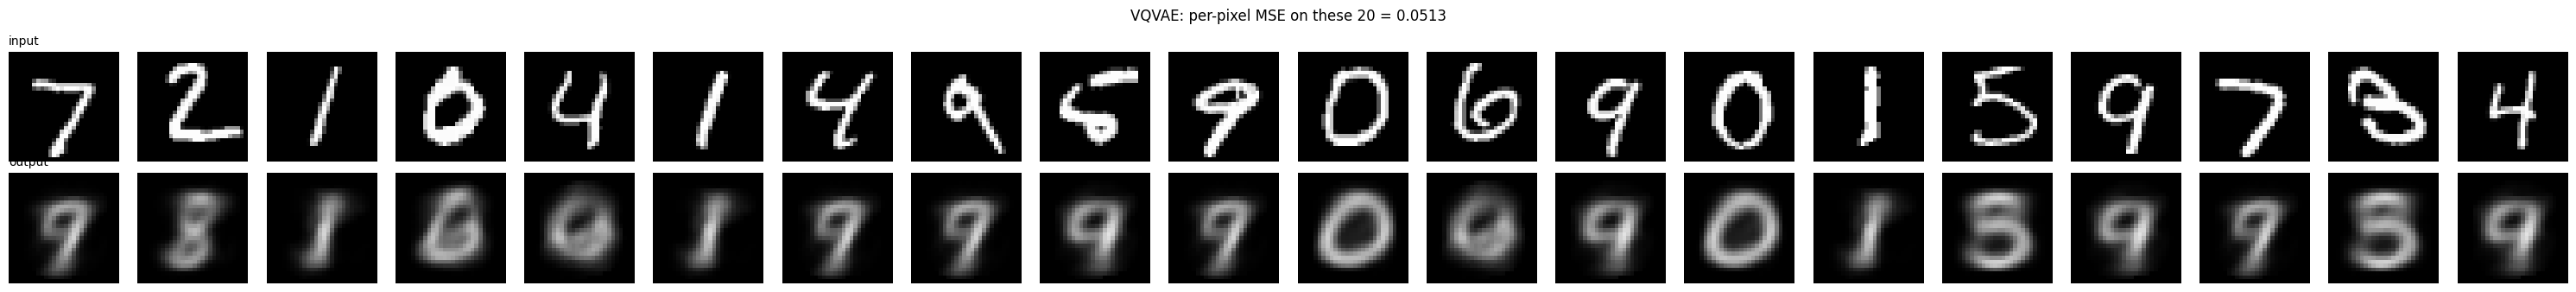

Epoch 12
-------------------------------
recon: 0.055198  vq: 0.009853  restarted: 0  [12800/60000]
recon: 0.055833  vq: 0.011043  restarted: 0  [25600/60000]
recon: 0.053262  vq: 0.011213  restarted: 0  [38400/60000]
recon: 0.052062  vq: 0.009882  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.053862  codes used: 10/10
Code counts: [1110, 1466, 1621, 926, 968, 1603, 390, 668, 681, 567]



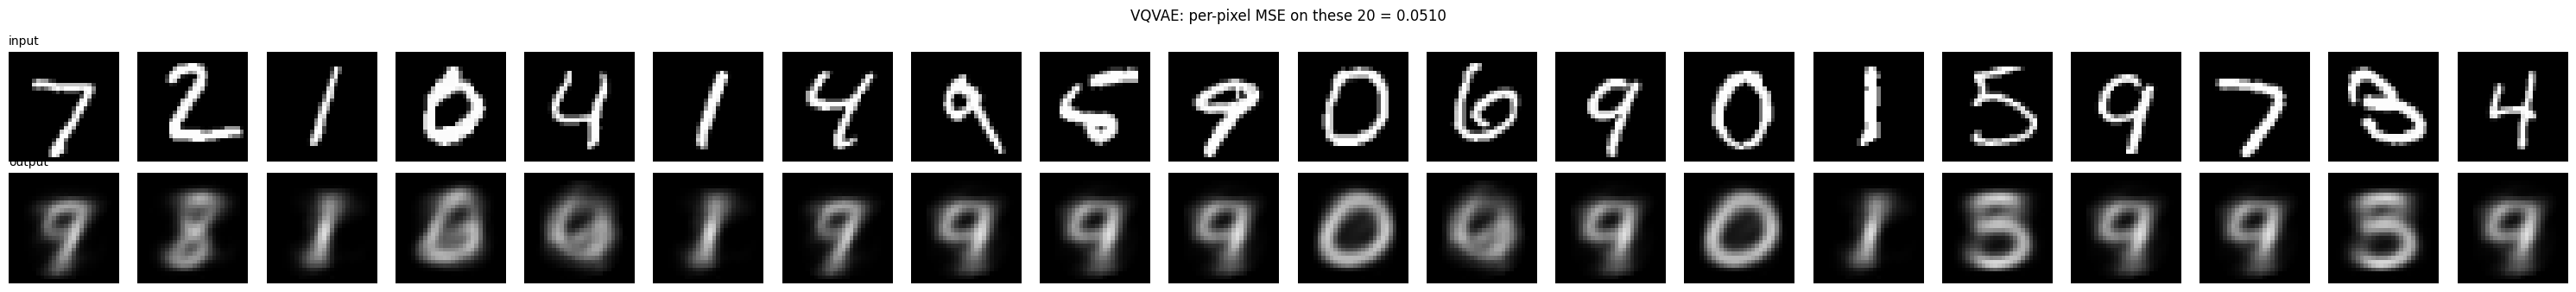

Epoch 13
-------------------------------
recon: 0.057368  vq: 0.011578  restarted: 0  [12800/60000]
recon: 0.055709  vq: 0.011715  restarted: 0  [25600/60000]
recon: 0.053099  vq: 0.009467  restarted: 0  [38400/60000]
recon: 0.054947  vq: 0.010424  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.053940  codes used: 10/10
Code counts: [1167, 1332, 1653, 1081, 875, 1277, 608, 796, 493, 718]



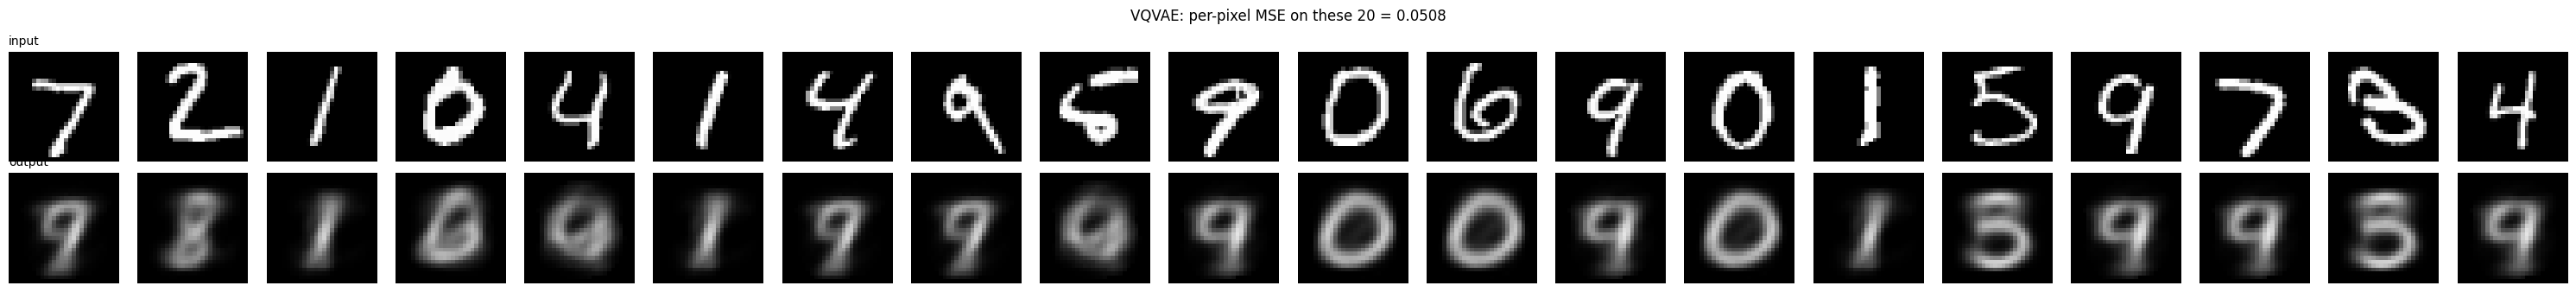

Epoch 14
-------------------------------
recon: 0.053909  vq: 0.010346  restarted: 0  [12800/60000]
recon: 0.056036  vq: 0.010511  restarted: 0  [25600/60000]
recon: 0.053219  vq: 0.009478  restarted: 0  [38400/60000]
recon: 0.055823  vq: 0.009764  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.054068  codes used: 10/10
Code counts: [1248, 1320, 1781, 1163, 823, 1113, 646, 683, 498, 725]



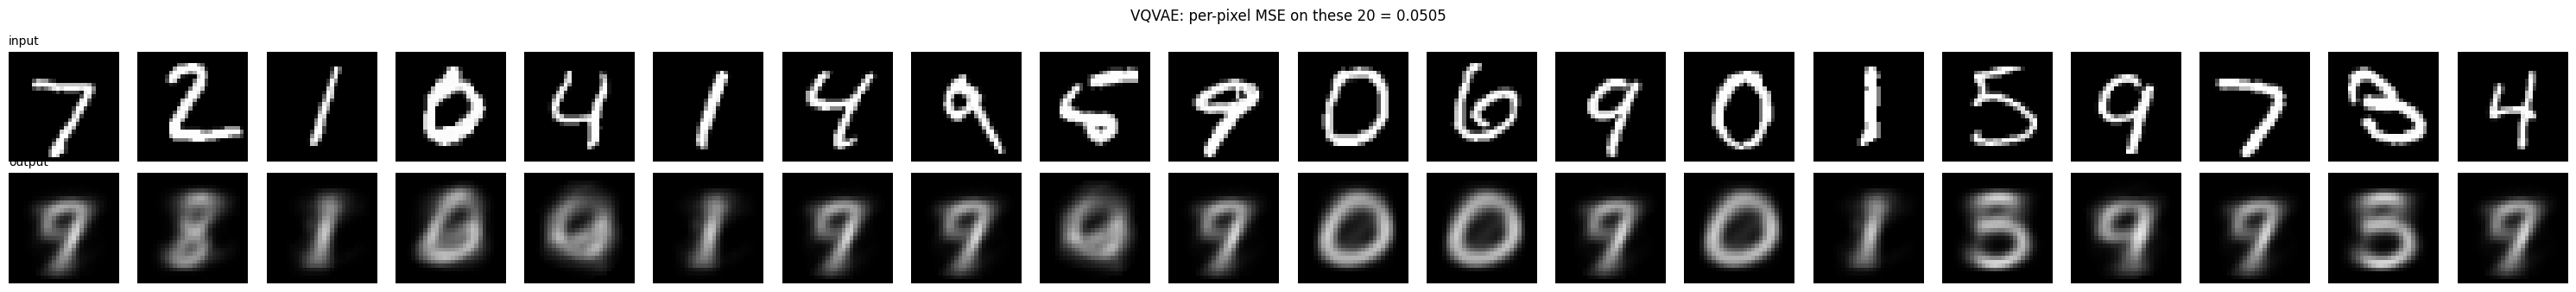

Epoch 15
-------------------------------
recon: 0.055846  vq: 0.012845  restarted: 0  [12800/60000]
recon: 0.053471  vq: 0.011232  restarted: 0  [25600/60000]
recon: 0.055416  vq: 0.009877  restarted: 0  [38400/60000]
recon: 0.053518  vq: 0.011714  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.054263  codes used: 10/10
Code counts: [1282, 1211, 1694, 1208, 850, 1086, 738, 600, 550, 781]



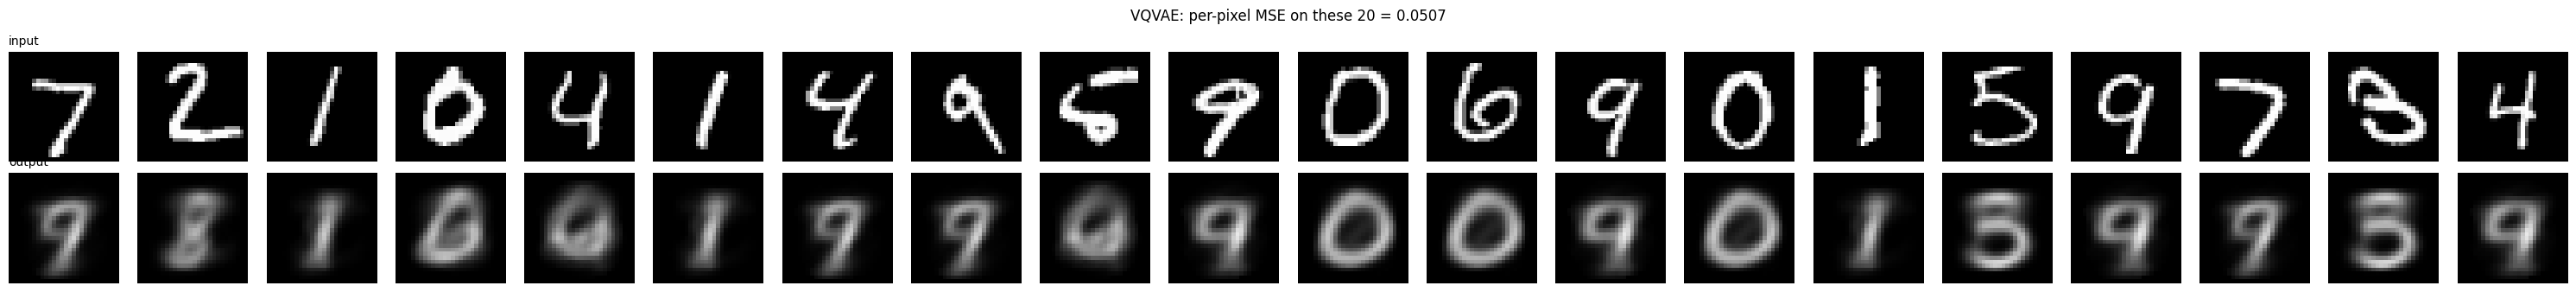

Epoch 16
-------------------------------
recon: 0.054997  vq: 0.011165  restarted: 0  [12800/60000]
recon: 0.053131  vq: 0.011602  restarted: 0  [25600/60000]
recon: 0.053370  vq: 0.010961  restarted: 0  [38400/60000]
recon: 0.054481  vq: 0.011859  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.053917  codes used: 10/10
Code counts: [1218, 1173, 1657, 1007, 910, 1320, 713, 601, 710, 691]



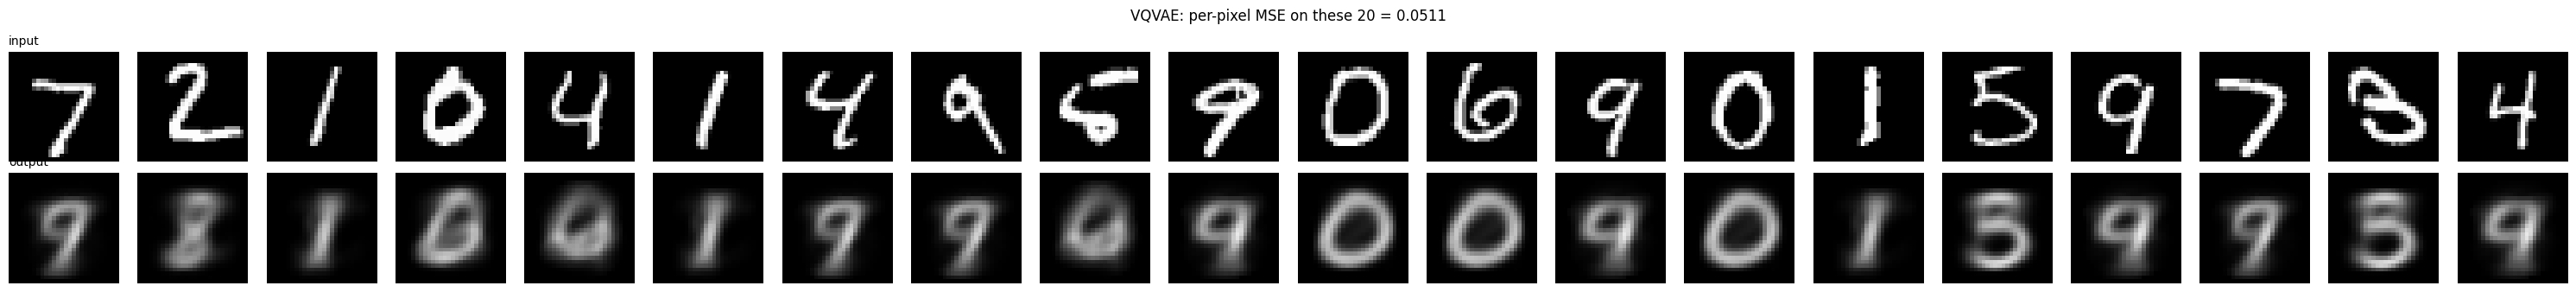

Epoch 17
-------------------------------
recon: 0.052962  vq: 0.010300  restarted: 0  [12800/60000]
recon: 0.054372  vq: 0.010960  restarted: 0  [25600/60000]
recon: 0.051732  vq: 0.010599  restarted: 0  [38400/60000]
recon: 0.055001  vq: 0.009830  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.053666  codes used: 10/10
Code counts: [1188, 1290, 1707, 894, 935, 1351, 644, 637, 677, 677]



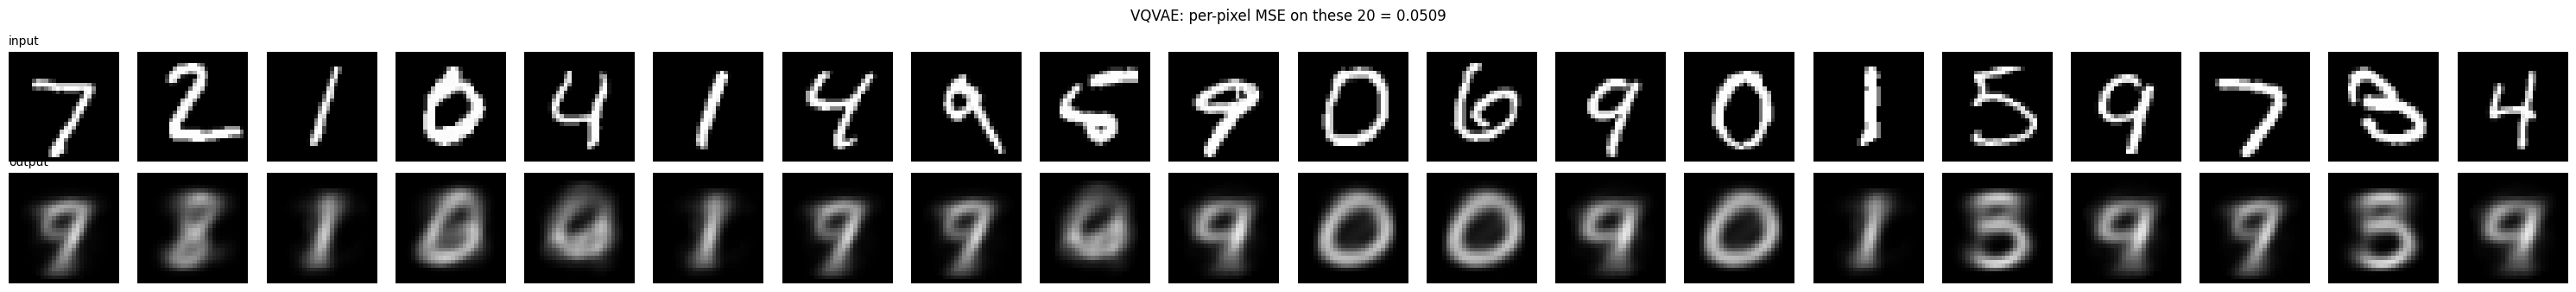

Epoch 18
-------------------------------
recon: 0.054608  vq: 0.013095  restarted: 0  [12800/60000]
recon: 0.057214  vq: 0.012398  restarted: 0  [25600/60000]
recon: 0.054486  vq: 0.011449  restarted: 0  [38400/60000]
recon: 0.054342  vq: 0.010256  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.053765  codes used: 10/10
Code counts: [1146, 1307, 1749, 875, 911, 1262, 758, 634, 692, 666]



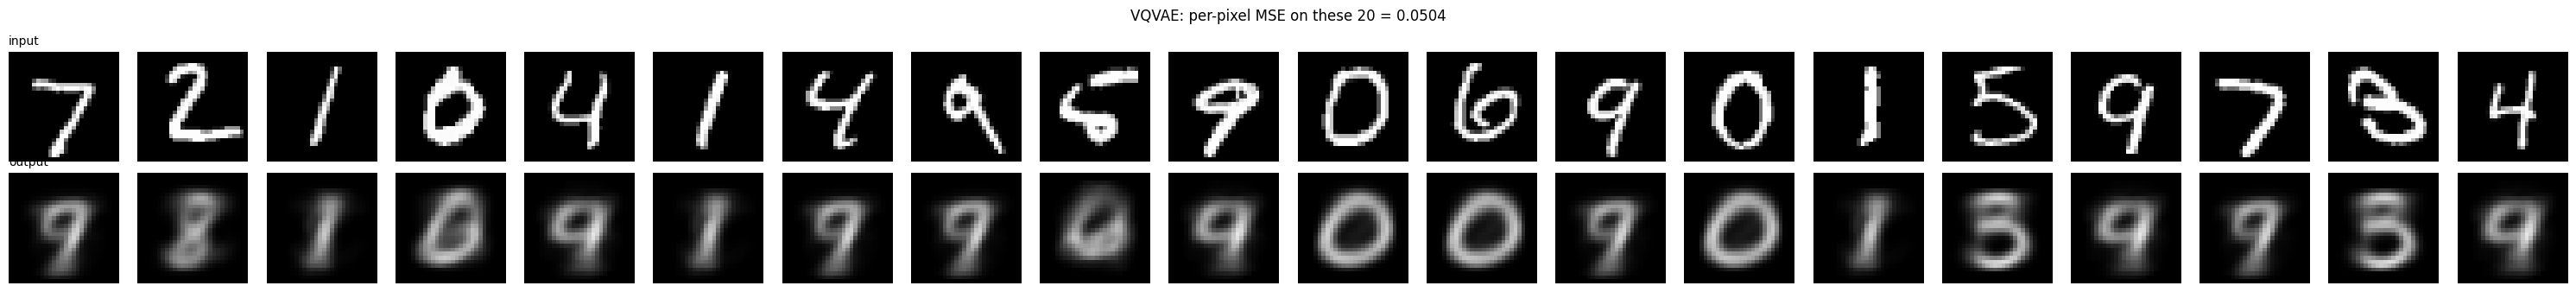

Epoch 19
-------------------------------
recon: 0.052733  vq: 0.010627  restarted: 0  [12800/60000]
recon: 0.053988  vq: 0.010189  restarted: 0  [25600/60000]
recon: 0.055022  vq: 0.011869  restarted: 0  [38400/60000]
recon: 0.055115  vq: 0.011679  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.054115  codes used: 10/10
Code counts: [1308, 1298, 1939, 978, 760, 1055, 833, 593, 648, 588]



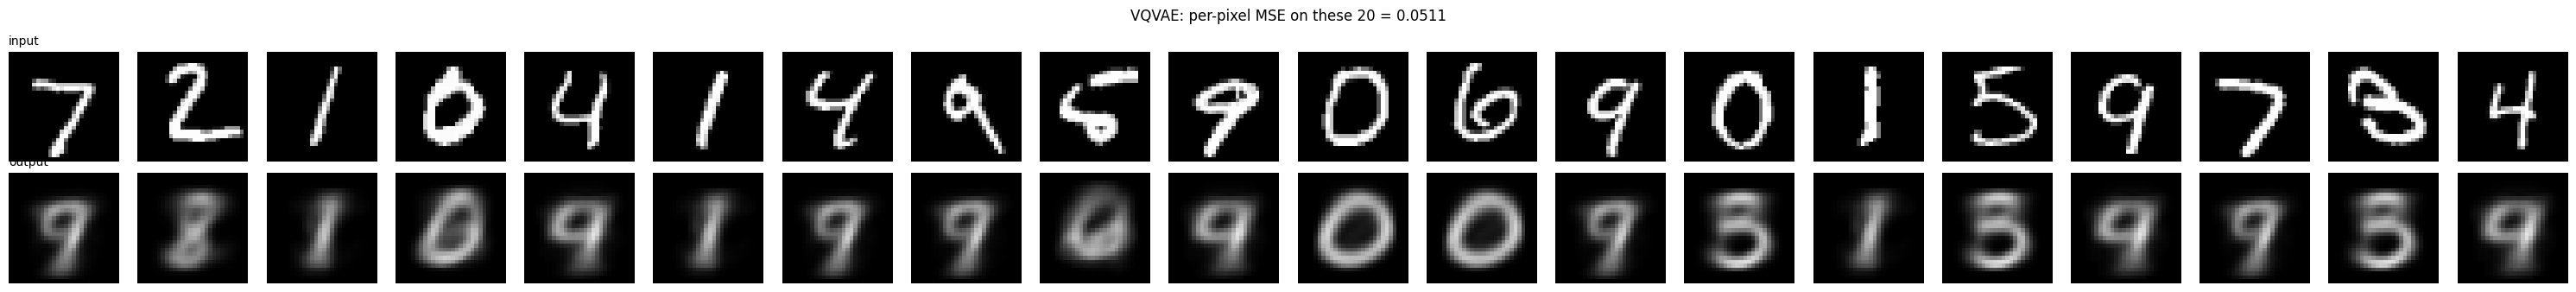

Epoch 20
-------------------------------
recon: 0.054572  vq: 0.011420  restarted: 0  [12800/60000]
recon: 0.052302  vq: 0.011477  restarted: 0  [25600/60000]
recon: 0.054334  vq: 0.012209  restarted: 0  [38400/60000]
recon: 0.053836  vq: 0.011632  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.053825  codes used: 10/10
Code counts: [1193, 1213, 1725, 844, 851, 1429, 729, 615, 756, 645]



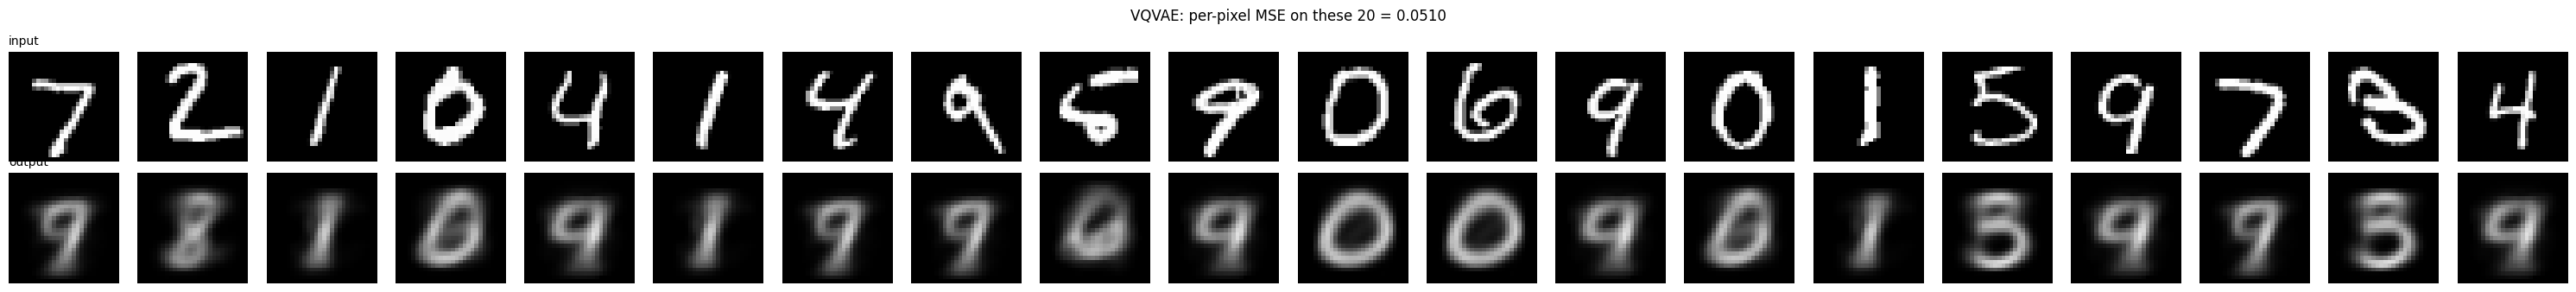

In [15]:

# Named separately so re-running this cell doesn't overwrite the AE's train/test
def train_vqvae(dataloader, model, loss_fn, optimizer, restart_every=100):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, _) in enumerate(dataloader):
        pred, vq_loss = model(X)
        recon_loss = loss_fn(pred, X)
        loss = recon_loss + vq_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch % restart_every == 0 and batch > 0:
            with torch.no_grad():
                n_dead = model.vq.restart_dead_codes(model.encoder(X))
            current = batch * len(X)
            print(f"recon: {recon_loss.item():>7f}  vq: {vq_loss.item():>7f}  restarted: {n_dead}  [{current:>5d}/{size:>5d}]")

def test_vqvae(dataloader, model, loss_fn):
    # Reports recon MSE only, so the number is comparable to the plain AE's
    model.eval()
    total, n = 0.0, 0
    counts = torch.zeros(model.vq.num_embeddings, dtype=torch.long)
    with torch.no_grad():
        for X, _ in dataloader:
            pred, _ = model(X)
            total += loss_fn(pred, X).item() * len(X)
            n += len(X)
            idx = model.vq.nearest_code(model.encoder(X))
            counts += torch.bincount(idx, minlength=len(counts))
    used = int((counts > 0).sum())
    print(f"Test recon MSE (per pixel): {total / n:>8f}  codes used: {used}/{len(counts)}")
    print(f"Code counts: {counts.tolist()}\n")
    
vqvae_model = VQVAE(latent_dim=32, num_embeddings=10, commitment_cost=0.25)

# Data-dependent codebook init from ~2048 encoder outputs
with torch.no_grad():
    init_x = torch.cat([X for X, _ in itertools.islice(train_dataloader, 32)])
    vqvae_model.vq.init_from_samples(vqvae_model.encoder(init_x))

optimizer = torch.optim.Adam(vqvae_model.parameters(), lr=1e-4)
epochs = 20
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_vqvae(train_dataloader, vqvae_model, loss_fn, optimizer)
    test_vqvae(test_dataloader, vqvae_model, loss_fn)
    show_reconstructions(vqvae_model, test_data, n=20)

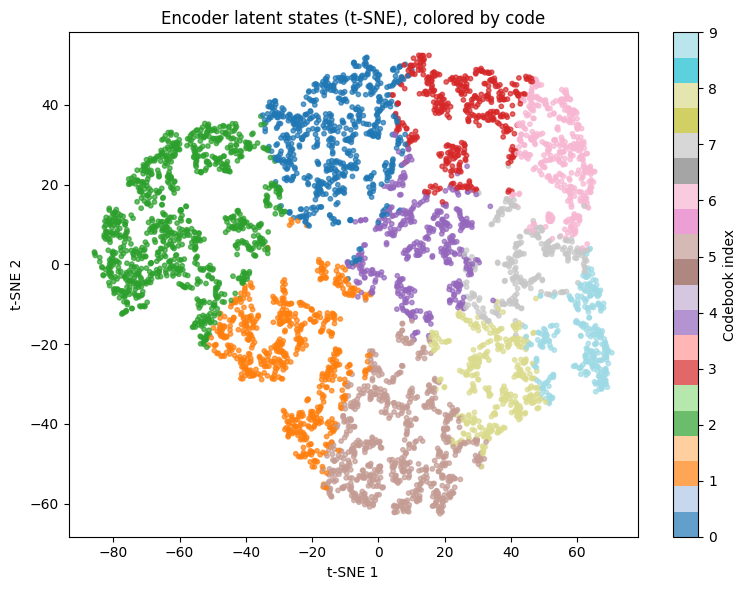

In [16]:
def plot_latent_distribution_tsne(model, dataloader, max_samples=5000, perplexity=30):
    model_was_training = model.training
    model.eval()
    device = next(model.parameters()).device

    latent_batches = []
    code_batches = []
    n_samples = 0

    try:
        with torch.no_grad():
            for images, _ in dataloader:
                images = images.to(device)
                z = model.encoder(images)
                codes = model.vq.nearest_code(z)

                remaining = max_samples - n_samples
                if remaining <= 0:
                    break

                latent_batches.append(z[:remaining].cpu())
                code_batches.append(codes[:remaining].cpu())
                n_samples += min(len(z), remaining)

                if n_samples >= max_samples:
                    break
    finally:
        model.train(model_was_training)

    latents = torch.cat(latent_batches).float()
    codes = torch.cat(code_batches)

    # t-SNE reduces the latent space to 2D while preserving neighborhood structure
    tsne = TSNE(
        n_components=2,
        perplexity=min(perplexity, max(2, len(latents) - 1)),
        random_state=42,
        init="pca",
        learning_rate="auto",
    )
    points = tsne.fit_transform(latents.numpy())
    code_ids = codes.numpy()

    fig, ax = plt.subplots(figsize=(8, 6))
    scatter = ax.scatter(
        points[:, 0],
        points[:, 1],
        c=code_ids,
        cmap="tab20",
        s=10,
        alpha=0.7,
    )
    ax.set_title("Encoder latent states (t-SNE), colored by code")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    fig.colorbar(scatter, ax=ax, label="Codebook index")
    plt.tight_layout()
    plt.show()


plot_latent_distribution_tsne(vqvae_model, test_dataloader, max_samples=5000, perplexity=30)

Not all codes are being utilized and there are multiple codes that represent the same input data. This is a common issue in VQ-VAE models, where the discrete latent space can lead to underutilization of the available codes.

The blur is a result of the latent space discretization. The VQ-VAE model uses a discrete latent space, which means that the continuous input data is mapped to a finite set of discrete codes (or means). When reconstructing the input data from these discrete codes, some information is inevitably lost, leading to a "smearing" effect in the output images. This loss of detail can be thought of as a form of regularization, where the model is forced to generalize and capture only the most salient features of the input data.

When the target is uncertain given what the model knows, a deterministic model can't output every possibility. It will make a compromise that is a blend of the possible outputs. This is the smearing. The probability mass will spread across different modes resulting in blur.

For $L^i$ norms, the smearing effect can be interpreted as follows:
- For $L^{0.5}$ norm, the model is more sensitive to small differences and will tend to the mode
- For $L^1$ norm, the model will produce the median of the possible outputs
- For $L^2$ norm, the model will produce the mean of the possible outputs

---


Still not satisfied with the results. How about we initialize the codebook with latent embeddings from the pretrained autoencoder?

Before fine-tuning:
Test recon MSE (per pixel): 0.067275  codes used: 10/10
Code counts: [792, 1250, 544, 1093, 1131, 1030, 1041, 581, 1291, 1247]

Epoch 1
-------------------------------


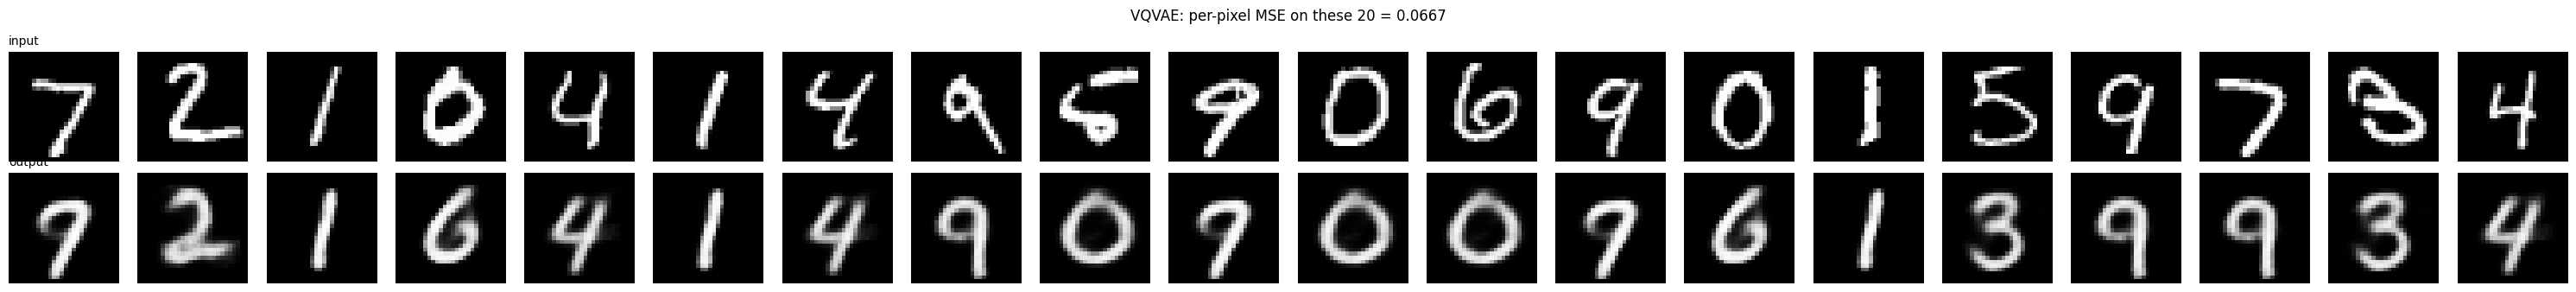

recon: 0.058378  vq: 0.872742  restarted: 0  [12800/60000]
recon: 0.053736  vq: 0.647507  restarted: 0  [25600/60000]
recon: 0.051443  vq: 0.543578  restarted: 0  [38400/60000]
recon: 0.052869  vq: 0.493428  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.053260  codes used: 10/10
Code counts: [929, 920, 590, 1089, 1186, 833, 1199, 196, 2286, 772]

Epoch 2
-------------------------------


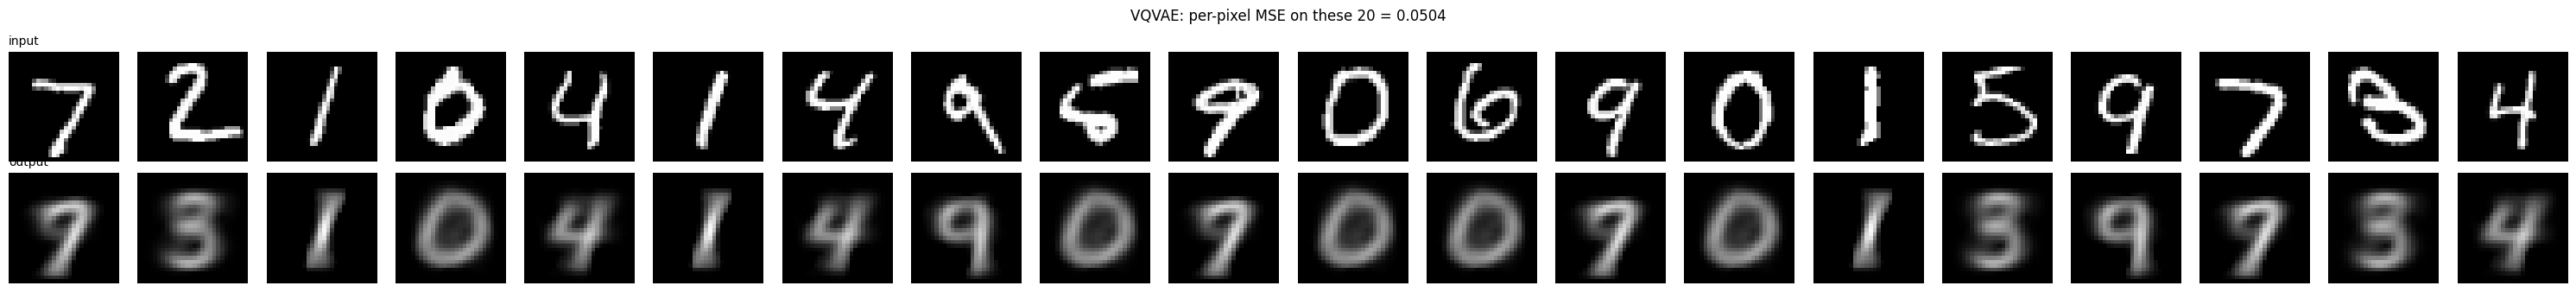

recon: 0.051582  vq: 0.393674  restarted: 0  [12800/60000]
recon: 0.055341  vq: 0.373402  restarted: 0  [25600/60000]
recon: 0.054985  vq: 0.374554  restarted: 0  [38400/60000]
recon: 0.052443  vq: 0.292954  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.053300  codes used: 10/10
Code counts: [797, 849, 675, 1109, 1209, 956, 1156, 76, 2648, 525]

Epoch 3
-------------------------------


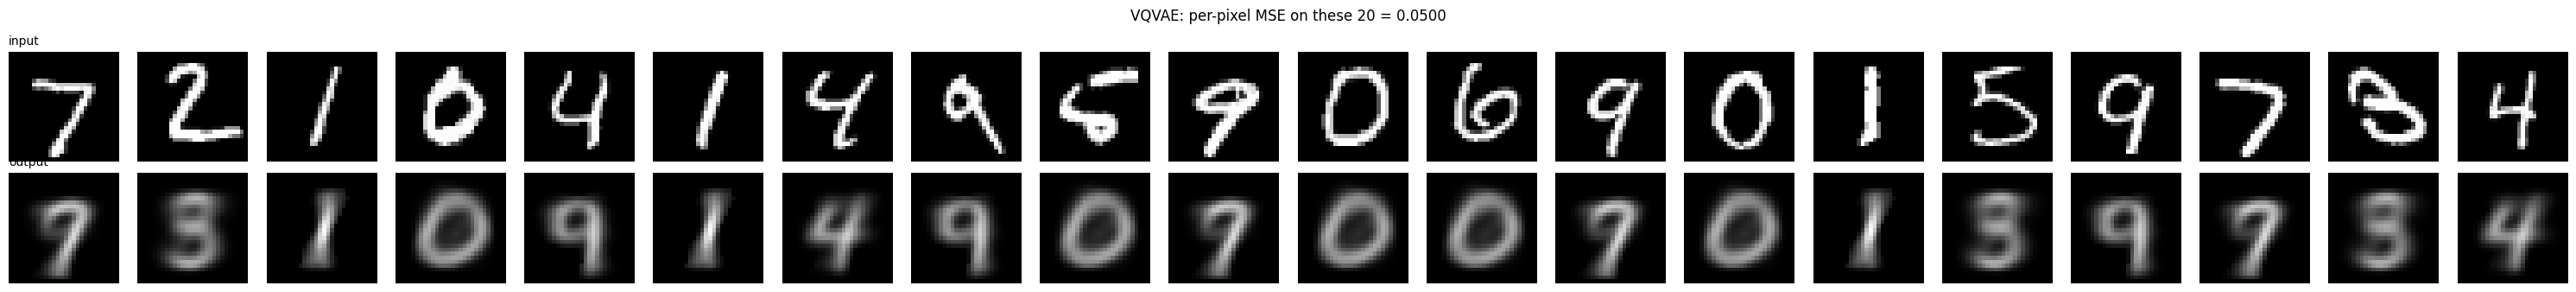

recon: 0.054251  vq: 0.303625  restarted: 0  [12800/60000]
recon: 0.053373  vq: 0.265670  restarted: 0  [25600/60000]
recon: 0.053358  vq: 0.264290  restarted: 0  [38400/60000]
recon: 0.050578  vq: 0.259947  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.053345  codes used: 10/10
Code counts: [637, 888, 700, 1114, 1229, 1093, 1049, 25, 2777, 488]

Epoch 4
-------------------------------


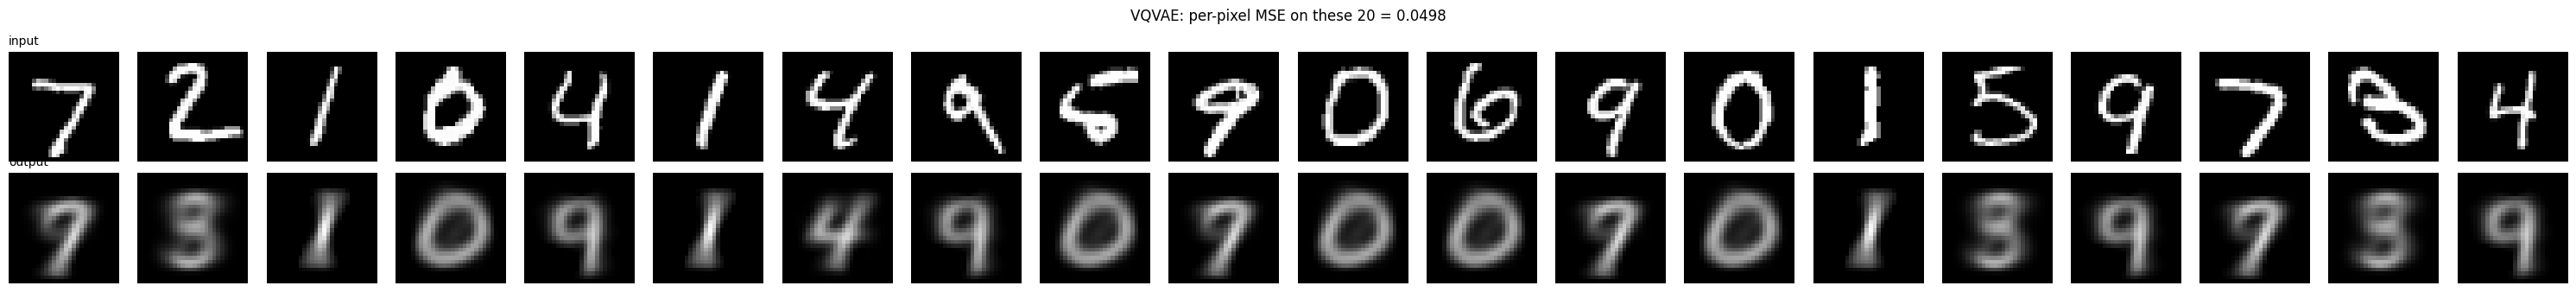

recon: 0.052478  vq: 0.240405  restarted: 0  [12800/60000]
recon: 0.054168  vq: 0.226653  restarted: 0  [25600/60000]
recon: 0.055024  vq: 0.238868  restarted: 0  [38400/60000]
recon: 0.054680  vq: 0.220208  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.053248  codes used: 10/10
Code counts: [560, 903, 717, 1121, 1215, 1189, 1003, 4, 2826, 462]

Epoch 5
-------------------------------


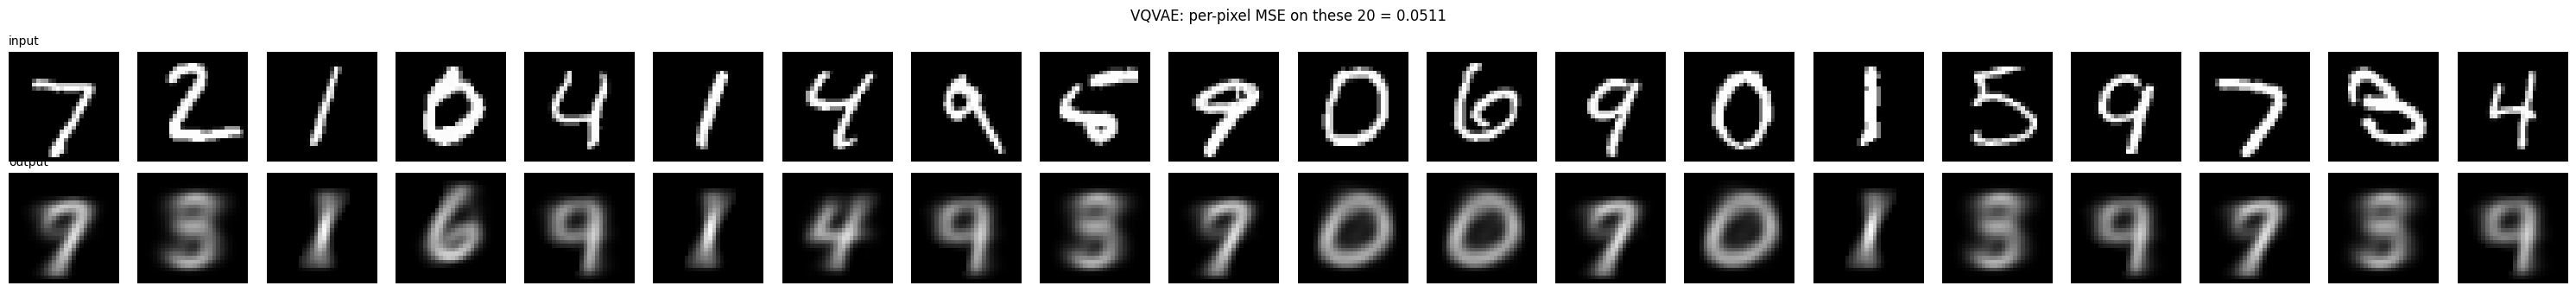

recon: 0.055151  vq: 0.200556  restarted: 0  [12800/60000]
recon: 0.051231  vq: 0.229067  restarted: 0  [25600/60000]
recon: 0.053293  vq: 0.172518  restarted: 0  [38400/60000]
recon: 0.052608  vq: 0.193855  restarted: 1  [51200/60000]
Test recon MSE (per pixel): 0.053228  codes used: 10/10
Code counts: [452, 877, 678, 1125, 1118, 994, 1019, 401, 2947, 389]

Epoch 6
-------------------------------


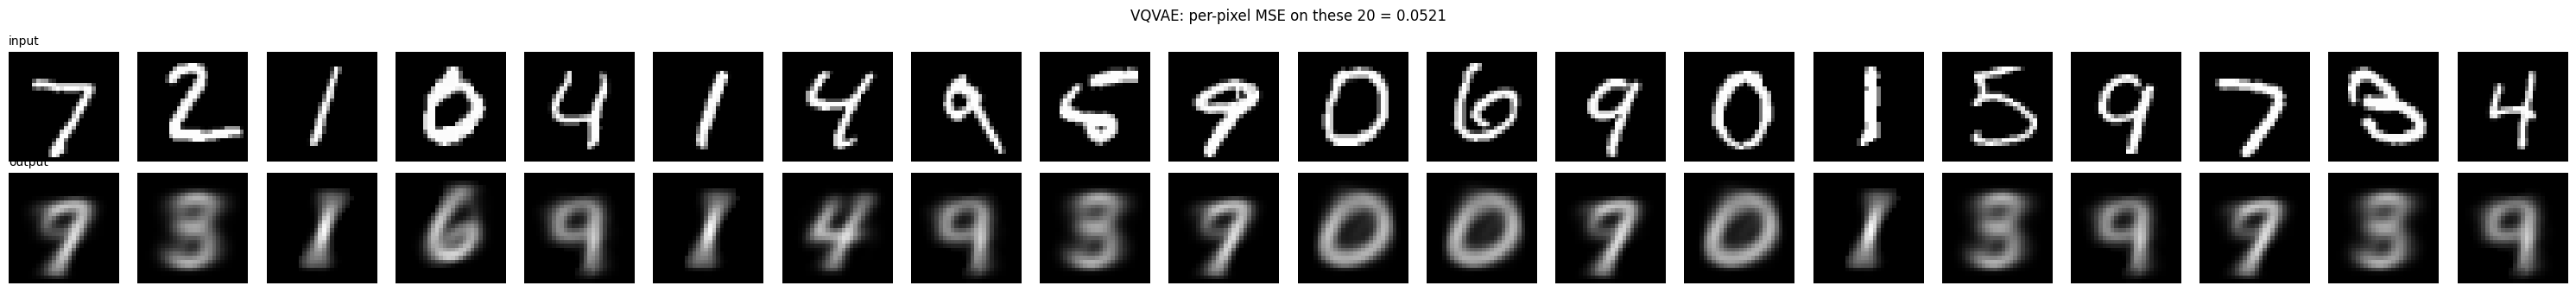

recon: 0.052722  vq: 0.175833  restarted: 0  [12800/60000]
recon: 0.053845  vq: 0.174712  restarted: 0  [25600/60000]
recon: 0.050468  vq: 0.171939  restarted: 0  [38400/60000]
recon: 0.053832  vq: 0.173792  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.052986  codes used: 10/10
Code counts: [431, 877, 677, 1122, 1059, 909, 1007, 571, 2956, 391]

Epoch 7
-------------------------------


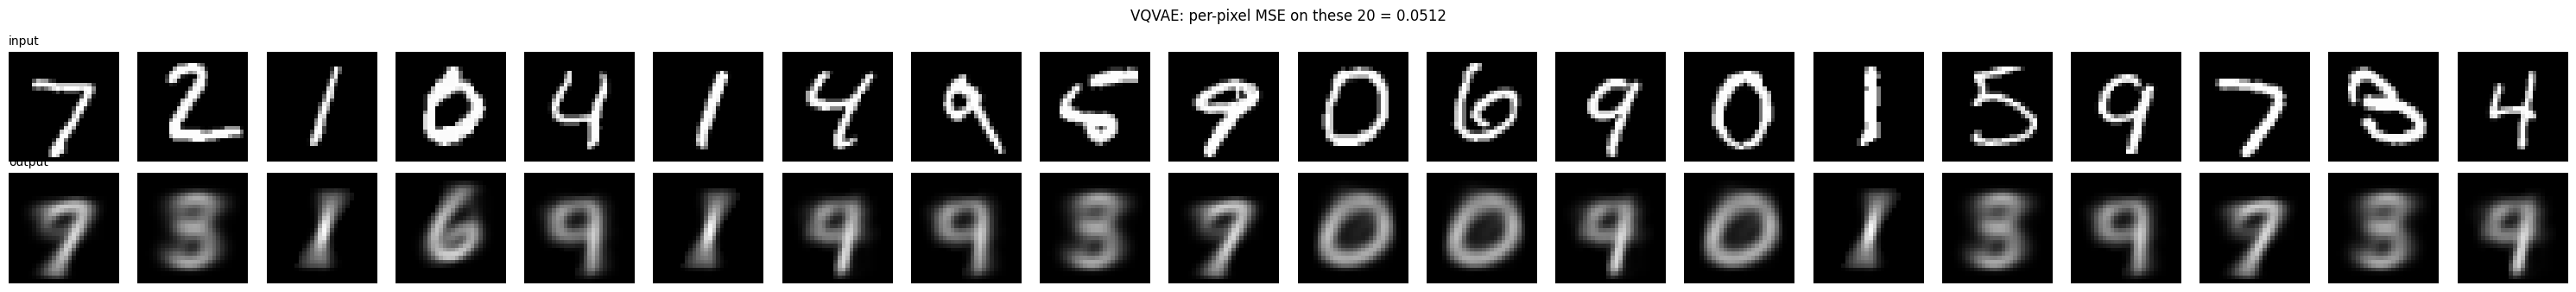

recon: 0.050043  vq: 0.148537  restarted: 0  [12800/60000]
recon: 0.054859  vq: 0.153354  restarted: 0  [25600/60000]
recon: 0.050976  vq: 0.152602  restarted: 0  [38400/60000]
recon: 0.053449  vq: 0.155445  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.052997  codes used: 10/10
Code counts: [386, 884, 662, 1124, 1017, 887, 983, 689, 2995, 373]

Epoch 8
-------------------------------


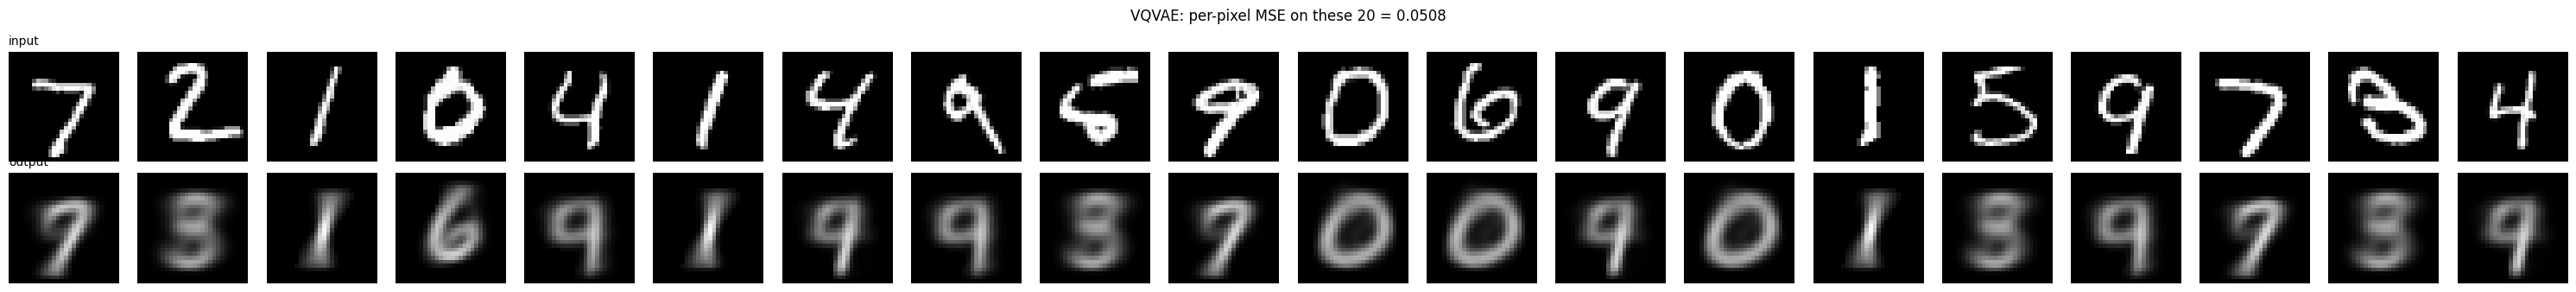

recon: 0.052873  vq: 0.140591  restarted: 0  [12800/60000]
recon: 0.054591  vq: 0.145629  restarted: 0  [25600/60000]
recon: 0.054088  vq: 0.133283  restarted: 0  [38400/60000]
recon: 0.053665  vq: 0.128098  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.052791  codes used: 10/10
Code counts: [370, 869, 653, 1121, 958, 900, 994, 748, 3000, 387]

Epoch 9
-------------------------------


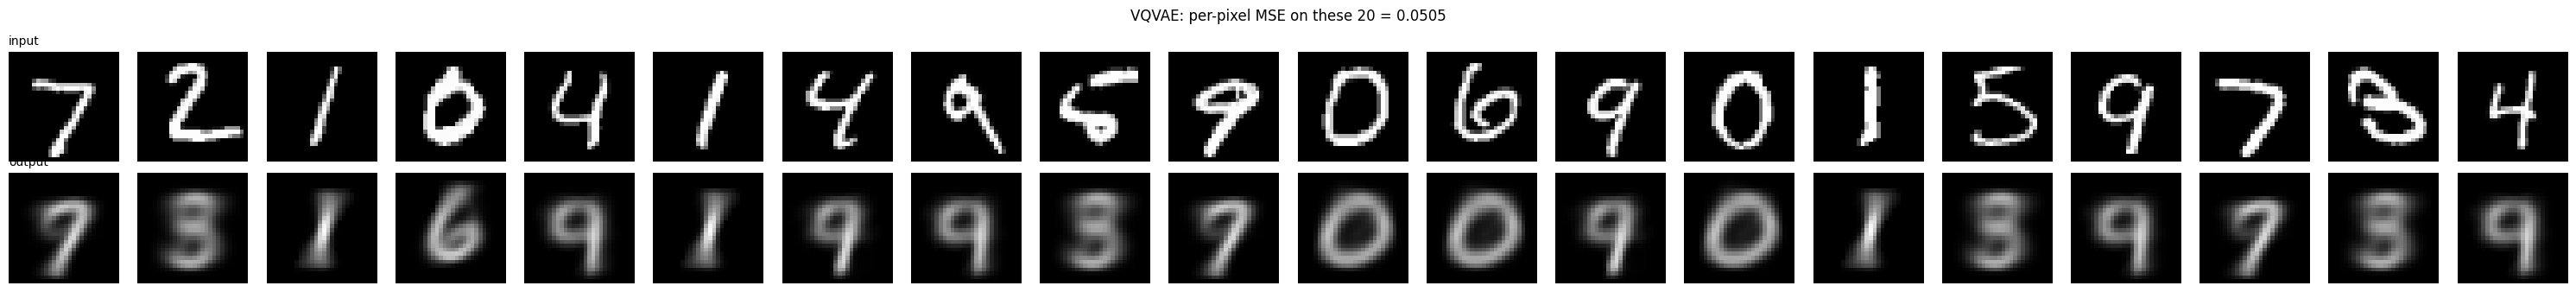

recon: 0.056299  vq: 0.146613  restarted: 0  [12800/60000]
recon: 0.051629  vq: 0.110902  restarted: 0  [25600/60000]
recon: 0.051800  vq: 0.115036  restarted: 0  [38400/60000]
recon: 0.053687  vq: 0.132021  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.052699  codes used: 10/10
Code counts: [358, 877, 659, 1123, 906, 882, 984, 829, 2997, 385]

Epoch 10
-------------------------------


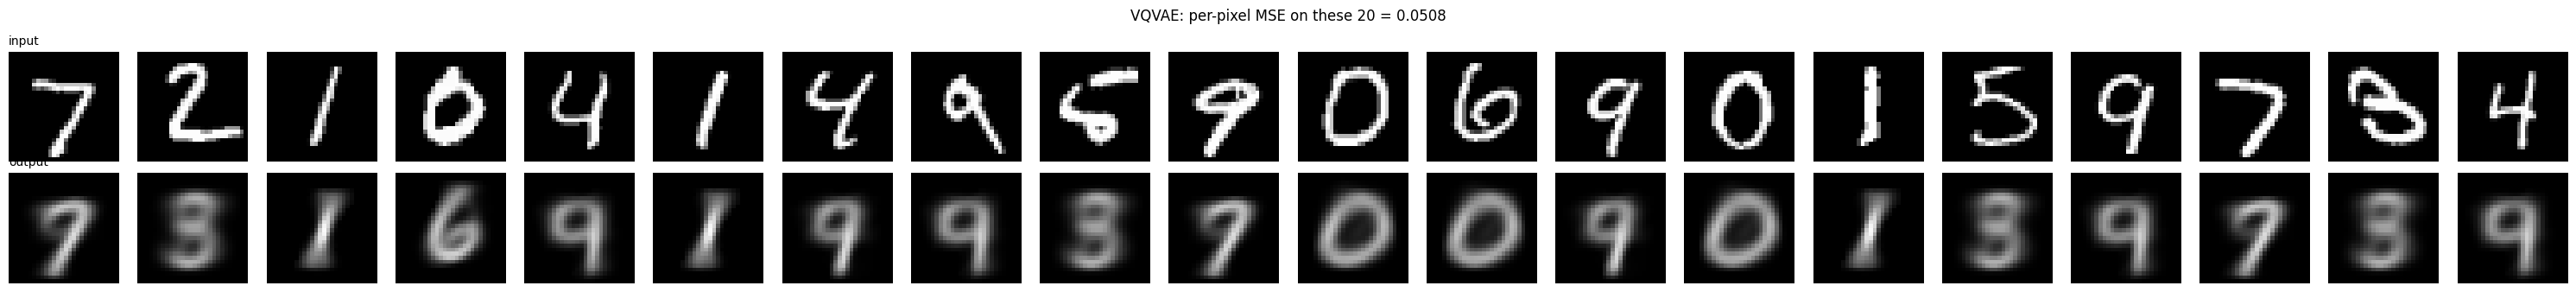

recon: 0.048955  vq: 0.105402  restarted: 0  [12800/60000]
recon: 0.053156  vq: 0.111885  restarted: 0  [25600/60000]
recon: 0.050461  vq: 0.114315  restarted: 0  [38400/60000]
recon: 0.053652  vq: 0.128165  restarted: 0  [51200/60000]
Test recon MSE (per pixel): 0.052742  codes used: 10/10
Code counts: [350, 863, 659, 1122, 887, 856, 991, 875, 3019, 378]



In [ ]:
import copy

vqvae_ae_model = VQVAE(latent_dim=32, num_embeddings=10, commitment_cost=0.25)
# Warm start from the AE: the codebook only makes sense in the space of the encoder that produced it
vqvae_ae_model.encoder = copy.deepcopy(ae_model.encoder)
vqvae_ae_model.decoder = copy.deepcopy(ae_model.decoder)

# k-means on ~10k pretrained AE latents
with torch.no_grad():
    init_x = torch.cat([X for X, _ in itertools.islice(train_dataloader, 80)])
    vqvae_ae_model.vq.init_from_samples(vqvae_ae_model.encoder(init_x))

print("Before fine-tuning:")
test_vqvae(test_dataloader, vqvae_ae_model, loss_fn)

# Optimizer built after the module swap so it holds the AE weights
optimizer = torch.optim.Adam(vqvae_ae_model.parameters(), lr=1e-4)
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    show_reconstructions(vqvae_ae_model, test_data, n=20)
    train_vqvae(train_dataloader, vqvae_ae_model, loss_fn, optimizer)
    test_vqvae(test_dataloader, vqvae_ae_model, loss_fn)